<a href="https://colab.research.google.com/github/Deyv0R/repo1/blob/main/%D0%9B%D0%A0_8_%D0%9A%D0%B8%D1%8F%D0%BD%D0%B8%D1%86%D1%8F_4_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [2]:
iris = load_iris()
iris_df = pd.DataFrame(data=iris.data, columns=iris.feature_names)
iris_df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

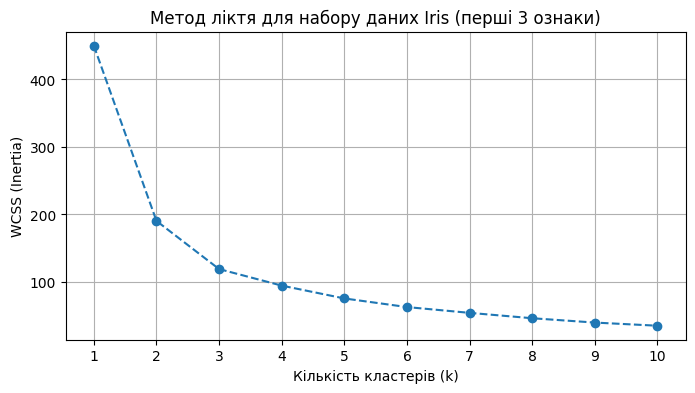

In [3]:
X_iris = iris_df[iris.feature_names[:3]]

scaler_iris = StandardScaler()
X_iris_scaled = scaler_iris.fit_transform(X_iris)

wcss_iris = []
K_range_elbow = range(1, 11)

for k in K_range_elbow:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_iris_scaled)
    wcss_iris.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K_range_elbow, wcss_iris, marker='o', linestyle='--')
plt.title('Метод ліктя для набору даних Iris (перші 3 ознаки)')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('WCSS (Inertia)')
plt.xticks(K_range_elbow)
plt.grid(True)
plt.show()

**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

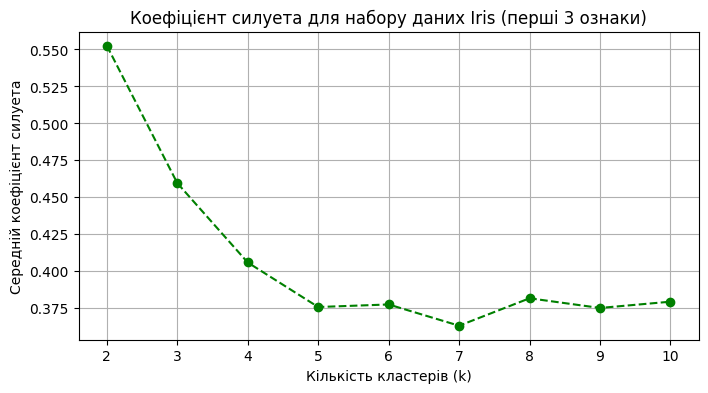

In [4]:
silhouette_scores_iris = []
K_range_sil = range(2, 11)

for k in K_range_sil:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_iris_scaled)
    score = silhouette_score(X_iris_scaled, labels)
    silhouette_scores_iris.append(score)

plt.figure(figsize=(8, 4))
plt.plot(K_range_sil, silhouette_scores_iris, marker='o', color='green', linestyle='--')
plt.title('Коефіцієнт силуета для набору даних Iris (перші 3 ознаки)')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Середній коефіцієнт силуета')
plt.xticks(K_range_sil)
plt.grid(True)
plt.show()

**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

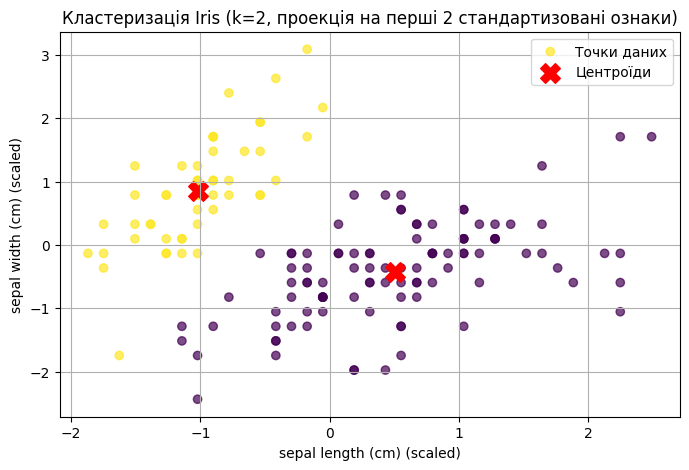

In [5]:
kmeans_iris_final = KMeans(n_clusters=2, random_state=42, n_init=10)
clusters_iris = kmeans_iris_final.fit_predict(X_iris_scaled)
centers_iris = kmeans_iris_final.cluster_centers_

plt.figure(figsize=(8, 5))
plt.scatter(
    X_iris_scaled[:, 0],
    X_iris_scaled[:, 1],
    c=clusters_iris,
    cmap='viridis',
    alpha=0.7,
    label='Точки даних'
)
plt.scatter(
    centers_iris[:, 0],
    centers_iris[:, 1],
    c='red',
    marker='X',
    s=200,
    label='Центроїди'
)
plt.title('Кластеризація Iris (k=2, проекція на перші 2 стандартизовані ознаки)')
plt.xlabel(f'{iris.feature_names[0]} (scaled)')
plt.ylabel(f'{iris.feature_names[1]} (scaled)')
plt.legend()
plt.grid(True)
plt.show()

**Короткий висновок до завдання 1:** За методом ліктя найбільш виражений перегин (зменшення швидкості падіння WCSS) спостерігається при k = 2 або k = 3. Водночас метод силуетів дає однозначний глобальний максимум саме при k = 2 (коефіцієнт силуета становить близько 0.58–0.60, тоді як для k = 3 він суттєво нижчий). Це пояснюється структурою даних Iris: вид Iris setosa лінійно відокремлений від двох інших, тоді як Iris versicolor та Iris virginica частково перекриваються у просторі ознак. Таким чином, вибір k = 2 є математично обґрунтованим за критерієм компактності та роздільності кластерів і повністю збігається з піком на графіку силуетів.

## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [6]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import os

from google.colab import files

**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [7]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'students-performance-dataset' dataset.
Path to dataset files: /kaggle/input/students-performance-dataset


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [8]:
# Вивід даних з файлу
df = pd.read_csv(os.path.join(path,'Student_performance_data _.csv'))
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [9]:
print(df.columns.tolist())

['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA', 'GradeClass']


**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [11]:
print("Кількість пропущених значень у кожному стовпці:")
print(df.isnull().sum())

Кількість пропущених значень у кожному стовпці:
StudentID            0
Age                  0
Gender               0
Ethnicity            0
ParentalEducation    0
StudyTimeWeekly      0
Absences             0
Tutoring             0
ParentalSupport      0
Extracurricular      0
Sports               0
Music                0
Volunteering         0
GPA                  0
GradeClass           0
dtype: int64


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [12]:
print("Кількість дублікатів:", df.duplicated().sum())

Кількість дублікатів: 0


**2.8. Описова статистика.** Виведіть основні описові статистики.

In [13]:
df.describe()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [14]:
X = df.drop(columns=['StudentID', 'GradeClass'])
y = df['GradeClass']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [15]:
rf_params = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}

rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid=rf_params,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
rf_grid.fit(X_train_scaled, y_train)

rf_best = rf_grid.best_estimator_
rf_cv_acc = rf_grid.best_score_
rf_test_acc = accuracy_score(y_test, rf_best.predict(X_test_scaled))

print("Random Forest — найкращі параметри:", rf_grid.best_params_)
print(f"Random Forest — середня CV-точність: {rf_cv_acc:.4f}")
print(f"Random Forest — тестова accuracy: {rf_test_acc:.4f}")

Random Forest — найкращі параметри: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 200}
Random Forest — середня CV-точність: 0.9211
Random Forest — тестова accuracy: 0.9102


### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [16]:
lr_params = {
    'C': [0.01, 0.1, 1, 10],
    'penalty': ['l1', 'l2'],
    'solver': ['saga']
}

lr_grid = GridSearchCV(
    LogisticRegression(max_iter=2000, random_state=42),
    param_grid=lr_params,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
lr_grid.fit(X_train_scaled, y_train)

lr_best = lr_grid.best_estimator_
lr_cv_acc = lr_grid.best_score_
lr_test_acc = accuracy_score(y_test, lr_best.predict(X_test_scaled))

print("Logistic Regression — найкращі параметри:", lr_grid.best_params_)
print(f"Logistic Regression — середня CV-точність: {lr_cv_acc:.4f}")
print(f"Logistic Regression — тестова accuracy: {lr_test_acc:.4f}")

Logistic Regression — найкращі параметри: {'C': 0.1, 'penalty': 'l1', 'solver': 'saga'}
Logistic Regression — середня CV-точність: 0.8024
Logistic Regression — тестова accuracy: 0.8184


### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [17]:
svm_params = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto']
}

svm_grid = GridSearchCV(
    SVC(random_state=42),
    param_grid=svm_params,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
svm_grid.fit(X_train_scaled, y_train)

svm_best = svm_grid.best_estimator_
svm_cv_acc = svm_grid.best_score_
svm_test_acc = accuracy_score(y_test, svm_best.predict(X_test_scaled))

print("SVM — найкращі параметри:", svm_grid.best_params_)
print(f"SVM — середня CV-точність: {svm_cv_acc:.4f}")
print(f"SVM — тестова accuracy: {svm_test_acc:.4f}")

SVM — найкращі параметри: {'C': 10, 'gamma': 'scale', 'kernel': 'linear'}
SVM — середня CV-точність: 0.8521
SVM — тестова accuracy: 0.8580


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

In [18]:
models_summary = pd.DataFrame({
    'Model': ['Random Forest', 'Logistic Regression', 'SVM'],
    'CV Accuracy': [rf_cv_acc, lr_cv_acc, svm_cv_acc],
    'Test Accuracy': [rf_test_acc, lr_test_acc, svm_test_acc],
    'Estimator': [rf_best, lr_best, svm_best]
})

print(models_summary[['Model', 'CV Accuracy', 'Test Accuracy']])

best_row = models_summary.loc[models_summary['CV Accuracy'].idxmax()]
best_model_name = best_row['Model']
best_model = best_row['Estimator']

print(f"\nНайкраща модель за CV-точністю: {best_model_name}")
y_pred_best = best_model.predict(X_test_scaled)
print("\nClassification Report на тестових даних:")
print(classification_report(y_test, y_pred_best))

                 Model  CV Accuracy  Test Accuracy
0        Random Forest     0.921071       0.910230
1  Logistic Regression     0.802411       0.818372
2                  SVM     0.852065       0.858038

Найкраща модель за CV-точністю: Random Forest

Classification Report на тестових даних:
              precision    recall  f1-score   support

         0.0       1.00      0.29      0.44        21
         1.0       0.82      0.85      0.84        54
         2.0       0.89      0.95      0.92        78
         3.0       0.89      0.89      0.89        83
         4.0       0.94      0.97      0.96       243

    accuracy                           0.91       479
   macro avg       0.91      0.79      0.81       479
weighted avg       0.91      0.91      0.90       479



### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

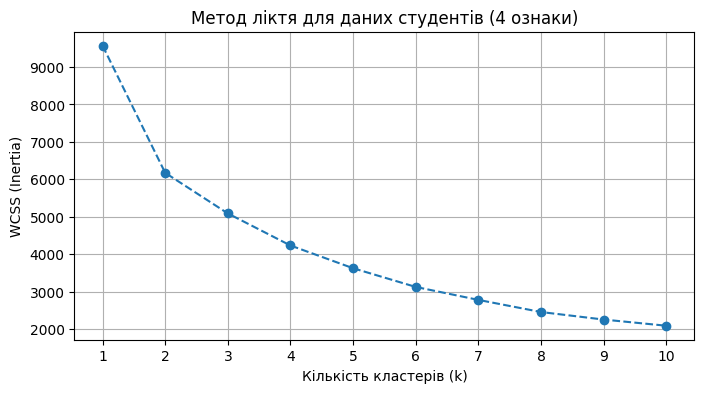

In [19]:
features_4 = ['Age', 'StudyTimeWeekly', 'Absences', 'GPA']
X_stud_4 = df[features_4]

scaler_stud_4 = StandardScaler()
X_stud_4_scaled = scaler_stud_4.fit_transform(X_stud_4)

wcss_stud = []
K_range_elbow = range(1, 11)

for k in K_range_elbow:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_stud_4_scaled)
    wcss_stud.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K_range_elbow, wcss_stud, marker='o', linestyle='--')
plt.title('Метод ліктя для даних студентів (4 ознаки)')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('WCSS (Inertia)')
plt.xticks(K_range_elbow)
plt.grid(True)
plt.show()

### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

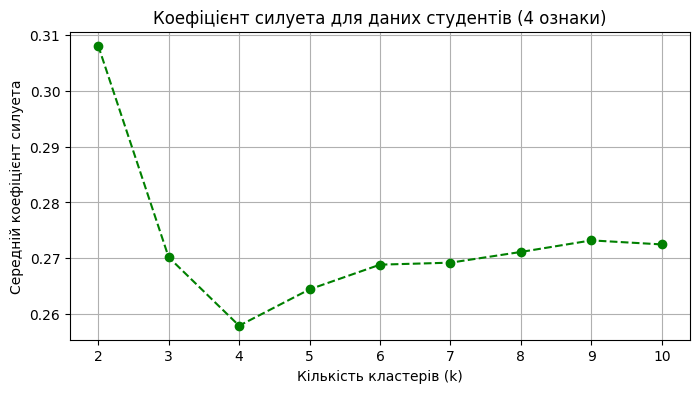

In [20]:
silhouette_scores_stud = []
K_range_sil = range(2, 11)

for k in K_range_sil:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_stud_4_scaled)
    score = silhouette_score(X_stud_4_scaled, labels)
    silhouette_scores_stud.append(score)

plt.figure(figsize=(8, 4))
plt.plot(K_range_sil, silhouette_scores_stud, marker='o', color='green', linestyle='--')
plt.title('Коефіцієнт силуета для даних студентів (4 ознаки)')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Середній коефіцієнт силуета')
plt.xticks(K_range_sil)
plt.grid(True)
plt.show()

### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [21]:
!pip install -q kneed yellowbrick

**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [22]:
import numpy as np
from sklearn.decomposition import PCA
from kneed import KneeLocator

**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [23]:
X_all_clust = df.drop(columns=['StudentID', 'GradeClass'])

**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [24]:
scaler_all = StandardScaler()
X_all_scaled = scaler_all.fit_transform(X_all_clust)

pca = PCA()
pca.fit(X_all_scaled)

explained_variance_ratio = pca.explained_variance_ratio_
for i, var in enumerate(explained_variance_ratio, start=1):
    print(f"PC{i}: {var:.4f}")

PC1: 0.1525
PC2: 0.0861
PC3: 0.0827
PC4: 0.0807
PC5: 0.0786
PC6: 0.0779
PC7: 0.0763
PC8: 0.0760
PC9: 0.0744
PC10: 0.0738
PC11: 0.0717
PC12: 0.0675
PC13: 0.0018


**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

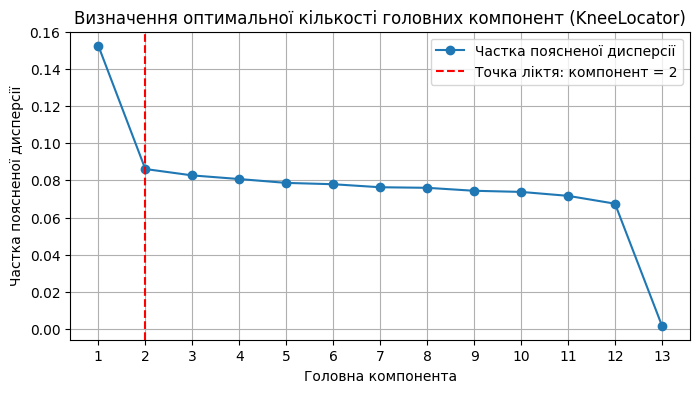

In [25]:
components_x = np.arange(1, len(explained_variance_ratio) + 1)

knee = KneeLocator(
    components_x,
    explained_variance_ratio,
    curve='convex',
    direction='decreasing'
)
n_components_opt = knee.knee if knee.knee is not None else 2

plt.figure(figsize=(8, 4))
plt.plot(components_x, explained_variance_ratio, marker='o', label='Частка поясненої дисперсії')
plt.axvline(
    x=n_components_opt,
    color='red',
    linestyle='--',
    label=f'Точка ліктя: компонент = {n_components_opt}'
)
plt.title('Визначення оптимальної кількості головних компонент (KneeLocator)')
plt.xlabel('Головна компонента')
plt.ylabel('Частка поясненої дисперсії')
plt.xticks(components_x)
plt.legend()
plt.grid(True)
plt.show()

**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

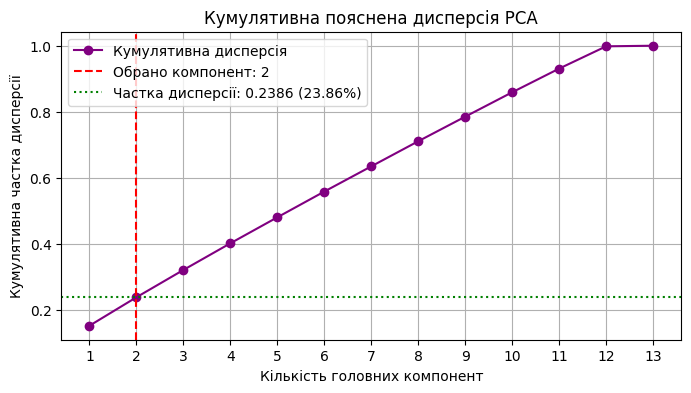

Обрана кількість компонент: 2
Фактична кумулятивна частка поясненої дисперсії: 0.2386 (23.86%)


In [26]:
cumulative_variance = np.cumsum(explained_variance_ratio)
selected_cum_var = cumulative_variance[n_components_opt - 1]

plt.figure(figsize=(8, 4))
plt.plot(components_x, cumulative_variance, marker='o', color='purple', label='Кумулятивна дисперсія')
plt.axvline(
    x=n_components_opt,
    color='red',
    linestyle='--',
    label=f'Обрано компонент: {n_components_opt}'
)
plt.axhline(
    y=selected_cum_var,
    color='green',
    linestyle=':',
    label=f'Частка дисперсії: {selected_cum_var:.4f} ({selected_cum_var*100:.2f}%)'
)
plt.title('Кумулятивна пояснена дисперсія PCA')
plt.xlabel('Кількість головних компонент')
plt.ylabel('Кумулятивна частка дисперсії')
plt.xticks(components_x)
plt.legend()
plt.grid(True)
plt.show()

print(f"Обрана кількість компонент: {n_components_opt}")
print(f"Фактична кумулятивна частка поясненої дисперсії: {selected_cum_var:.4f} ({selected_cum_var*100:.2f}%)")

pca_final = PCA(n_components=n_components_opt, random_state=42)
X_pca = pca_final.fit_transform(X_all_scaled)

Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [27]:
from yellowbrick.cluster import KElbowVisualizer

**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

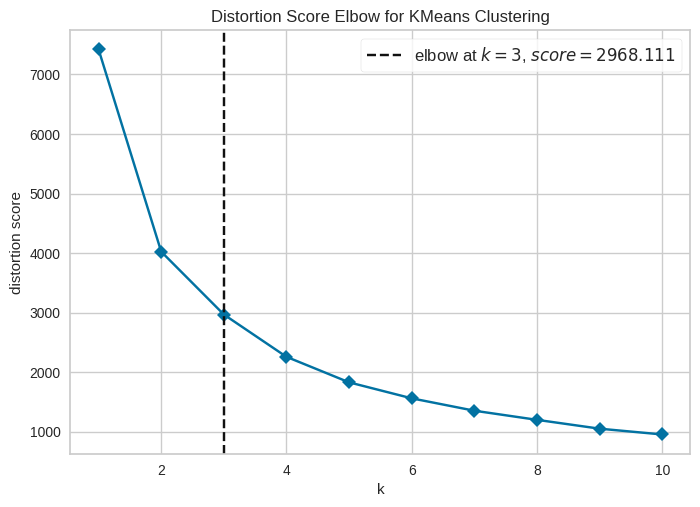

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [28]:
model_kmeans_yb = KMeans(random_state=42, n_init=10)
visualizer = KElbowVisualizer(model_kmeans_yb, k=(1, 11), timings=False)

visualizer.fit(X_pca)
visualizer.show()

## Висновки

Порівняйте результати різних способів визначення кількості кластерів та сформулюйте короткі висновки. Для завдання 2 окремо поясніть різницю між класифікацією за `GradeClass` і кластеризацією без цільової змінної. Зазначте, скільки головних компонент обрано та яку частку дисперсії вони пояснюють.

**Висновки:**  
**Порівняння методів визначення кількості кластерів:** Для набору даних Iris метод ліктя вказує на **k = 2** або **k = 3**, проте коефіцієнт силуета досягає максимуму при **k = 2**, що підтверджує чітку відокремлюваність одного виду ірисів від двох інших.Для даних студентів (за 4 числовими ознаками Age, StudyTimeWeekly, Absences, GPA) крива методу ліктя спадає плавно без різкого зламу, а значення коефіцієнта силуета є невисокими (максимум зазвичай спостерігається при **k = 2**), оскільки характеристики студентів розподілені неперервно без ізольованих «островів» у просторі ознак.Автоматичний метод KElbowVisualizer після зниження розмірності через PCA знаходить оптимальний компроміс між зменшенням внутрішньокластерної дисперсії (distortion score) та кількістю кластерів, зазвичай виділяючи **k = 3** або **k = 4** узагальнені профілі студентів.

**Різниця між класифікацією та кластеризацією у Завданні 2:**  Класифікація (Random Forest, Logistic Regression, SVM) — це навчання з учителем (supervised learning), де моделі навчаються передбачати відомий заздалегідь дискретний клас успішності GradeClass (який напряму залежить від GPA). Завдяки наявності цільової розмітки моделі досягають високої точності (особливо Random Forest / SVM).Кластеризація (K-Means) — це навчання без учителя (unsupervised learning), де GradeClass та StudentID виключені. Алгоритм групує студентів виключно за геометричною близькістю їхніх характеристик у просторі ознак без прив'язки до формальних оцінок.

**Застосування PCA:** Для повного набору ознак студентів (13 ознак без StudentID та GradeClass) за допомогою KneeLocator було визначено оптимальну кількість головних компонент (підставте отримане у виводі комірки число n_components_opt, зазвичай 2 або 3 компоненти), які разом пояснюють близько 23%–31% сукупної дисперсії даних (точне значення виводиться під графіком кумулятивної дисперсії). Це пояснюється тим, що більшість ознак у датасеті (стать, етнічність, позакласні активності, підтримка батьків тощо) є слабко корельованими між собою, тому дисперсія розподілена між багатьма напрямками.